# Customer Churn Prediction: Data Understanding

This notebook covers **Step 2: Dataset Selection, Loading & Initial Data Understanding** for the Customer Churn Prediction project.
It loads the raw dataset, inspects its structure and schema, validates data quality using our reusable `src.data` package, and documents critical initial findings.

## 1. Objective

Customer churn represents the loss of clients or customers over a specified billing period. In the telecommunications sector, retaining existing customers is significantly more cost-effective than acquiring new ones.

**Goals of this phase:**
- Ingest the raw customer data safely using standardized, validated loading pipelines.
- Understand dataset dimensions, schema, and column data types.
- Check data integrity (missing values, duplicate records, hidden whitespace).
- Analyze the target variable (`Churn`) and quantify class distribution.
- Establish baseline findings to guide subsequent Exploratory Data Analysis (EDA) and preprocessing steps.

## 2. Dataset Information

- **Dataset**: IBM Telco Customer Churn
- **Total Records**: 7,043 customers
- **Total Features**: 21 columns (1 customer ID, 19 predictive features, 1 target)
- **Target Feature**: `Churn` (Binary: `Yes` / `No`)
- **Storage Location**: `data/raw/telco_customer_churn.csv` (strictly immutable)

## 3. Import Libraries

Import essential data manipulation libraries, plotting packages, and modular functions from `src.data`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Ensure project root is in Python path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (
    check_duplicates,
    check_missing_values,
    generate_data_quality_report,
    get_column_info,
    get_dataset_shape,
    identify_feature_types,
    load_dataset,
    validate_target,
)

print("Libraries and modular components imported successfully.")

Libraries and modular components imported successfully.


## 4. Load Dataset

Load the immutable raw CSV file using `load_dataset`.

In [2]:
data_path = PROJECT_ROOT / "data" / "raw" / "telco_customer_churn.csv"
df = load_dataset(data_path)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 5. Dataset Shape

Inspect the total count of observations and attributes.

In [3]:
rows, cols = get_dataset_shape(df)
print(f"Dataset Dimensions: {rows:,} rows across {cols} columns")

Dataset Dimensions: 7,043 rows across 21 columns


## 6. Dataset Columns

Review all column names and dataset memory footprint.

In [4]:
col_info = get_column_info(df)
print(f"Total columns: {col_info['total_columns']}")
print(f"Memory usage: {col_info['memory_usage_mb']:.2f} MB\n")
print("Column list:")
for i, col in enumerate(col_info["column_names"], 1):
    print(f"  {i:2d}. {col}")

Total columns: 21
Memory usage: 6.82 MB

Column list:
   1. customerID
   2. gender
   3. SeniorCitizen
   4. Partner
   5. Dependents
   6. tenure
   7. PhoneService
   8. MultipleLines
   9. InternetService
  10. OnlineSecurity
  11. OnlineBackup
  12. DeviceProtection
  13. TechSupport
  14. StreamingTV
  15. StreamingMovies
  16. Contract
  17. PaperlessBilling
  18. PaymentMethod
  19. MonthlyCharges
  20. TotalCharges
  21. Churn


## 7. Data Types

Examine data types inferred by pandas.

In [5]:
dtypes_df = pd.DataFrame(
    {
        "Column": list(col_info["dtypes"].keys()),
        "Dtype": list(col_info["dtypes"].values()),
    }
)
dtypes_df

,Column,Dtype
0,customerID,str
1,gender,str
2,SeniorCitizen,int64
3,Partner,str
4,Dependents,str
5,tenure,int64
6,PhoneService,str
7,MultipleLines,str
8,InternetService,str
9,OnlineSecurity,str


## 8. Missing Values

Assess standard missing (`NaN` / `None`) counts across columns.

In [6]:
missing_series = check_missing_values(df)
print(f"Total standard null values across entire dataset: {missing_series.sum()}")
missing_series

Total standard null values across entire dataset: 0


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 9. Duplicate Records

Check for repeated customer records.

In [7]:
duplicates = check_duplicates(df)
print(f"Number of fully duplicated rows: {duplicates}")

Number of fully duplicated rows: 0


## 10. Numerical Features

Identify numerical variables and generate summary statistics.

In [8]:
feature_groups = identify_feature_types(df, target_col="Churn", id_cols=["customerID"])
print(f"Numerical features detected: {feature_groups['numerical']}")
df[feature_groups["numerical"]].describe().round(2)

Numerical features detected: ['SeniorCitizen', 'tenure', 'MonthlyCharges']


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


## 11. Categorical Features

Identify categorical variables and inspect unique category counts.

In [9]:
cat_cols = feature_groups["categorical"]
print(f"Categorical features ({len(cat_cols)}): {cat_cols}\n")
cat_summary = pd.DataFrame(
    {
        "Feature": cat_cols,
        "Unique_Values": [df[c].nunique() for c in cat_cols],
        "Sample_Values": [df[c].unique()[:3].tolist() for c in cat_cols],
    }
)
cat_summary

Categorical features (16): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']



,Feature,Unique_Values,Sample_Values
0,gender,2,"[Female, Male]"
1,Partner,2,"[Yes, No]"
2,Dependents,2,"[No, Yes]"
3,PhoneService,2,"[No, Yes]"
4,MultipleLines,3,"[No phone service, No, Yes]"
5,InternetService,3,"[DSL, Fiber optic, No]"
6,OnlineSecurity,3,"[No, Yes, No internet service]"
7,OnlineBackup,3,"[Yes, No, No internet service]"
8,DeviceProtection,3,"[No, Yes, No internet service]"
9,TechSupport,3,"[No, Yes, No internet service]"


## 12. Target Variable

Validate the target column `Churn`.

In [10]:
target_validation = validate_target(df, target_col="Churn")
for key, val in target_validation.items():
    print(f"{key}: {val}")

target_column: Churn
is_present: True
unique_values: ['No', 'Yes']
value_counts: {'No': 5174, 'Yes': 1869}
proportions: {'No': 0.7346, 'Yes': 0.2654}
missing_count: 0
is_imbalanced: True
imbalance_ratio: 2.768


## 13. Target Distribution

Examine class imbalance and visualize target proportions.

       Count  Percentage (%)
Churn                       
No      5174           73.46
Yes     1869           26.54


/tmp/ipykernel_35614/2903003941.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=["#2b5c8f", "#e74c3c"], ax=ax)


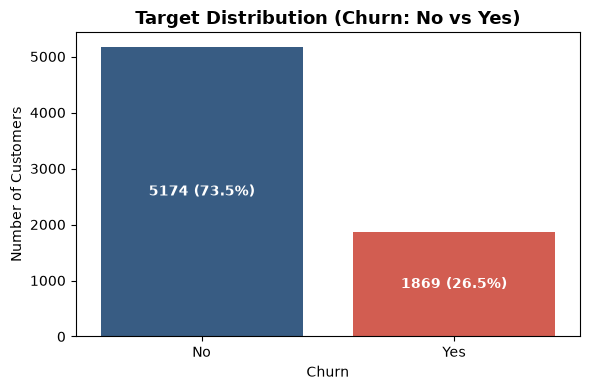

In [11]:
churn_counts = df["Churn"].value_counts()
churn_pcts = df["Churn"].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({"Count": churn_counts, "Percentage (%)": churn_pcts.round(2)})
print(dist_df)

# Visualization
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=churn_counts.index, y=churn_counts.values, palette=["#2b5c8f", "#e74c3c"], ax=ax
)
ax.set_title("Target Distribution (Churn: No vs Yes)", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Customers")
ax.set_xlabel("Churn")
for p in ax.patches:
    height = p.get_height()
    pct = (height / len(df)) * 100
    ax.annotate(
        f"{int(height)} ({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, height / 2),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

## 14. Initial Data Quality Findings

Execute full data quality check including detection of hidden whitespace values in `TotalCharges`.

In [12]:
quality_report = generate_data_quality_report(df, target_col="Churn")
suspicious = quality_report["suspicious_values"]
print("Suspicious values detection:")
print(f"Has suspicious values: {suspicious['has_suspicious_values']}")
for col, details in suspicious["columns_with_suspicious_values"].items():
    print(
        f"  - Column '{col}': {details['whitespace_count']} whitespace entries (Sample indices: {details['sample_indices']})"
    )

# Inspect zero-tenure records with whitespace in TotalCharges
sample_ws_idx = suspicious["columns_with_suspicious_values"]["TotalCharges"][
    "sample_indices"
]
print("\nSample records with whitespace TotalCharges:")
df.loc[
    sample_ws_idx, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Column 'TotalCharges' contains 11 suspicious values (0.16%)


Suspicious values detection:
Has suspicious values: True
  - Column 'TotalCharges': 11 whitespace entries (Sample indices: [488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670])

Sample records with whitespace TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


## 15. Next Steps

With the dataset successfully loaded and audited, the subsequent workflow steps are:

1. **Step 3 — Exploratory Data Analysis (EDA)**:
   - Analyze distributions of tenure, monthly charges, and total charges.
   - Examine churn rates across contract types, payment methods, and internet service categories.
   - Compute correlation matrices and demographic insights.

2. **Step 4 — Data Preprocessing & Feature Engineering**:
   - Convert `TotalCharges` to numeric float and impute missing values (zero-tenure customers set to 0.0).
   - Encode categorical features (one-hot encoding / binary mapping).
   - Drop non-predictive identifier (`customerID`).
   - Partition data into stratified Train, Validation, and Test splits.

3. **Step 5 — Baseline Modeling**:
   - Train baseline models (DummyClassifier, Logistic Regression).
   - Track performance using ROC-AUC, PR-AUC, and F1-score to account for the ~26.5% class imbalance.